# Лабораторная 1. Среда, данные и первая сводка

Задание целиком: `labs/lab01/README.md` в репозитории курса.

Как работать с ноутбуком:
1. В первой ячейке впишите свой номер варианта.
2. Заполните ячейки с пометкой `TODO` по порядку. Подсказки в комментариях.
3. В конце выполните Run All с нуля, скачайте ноутбук и `results.zip`.

Ноутбук работает в Kaggle, Colab и локально. В Kaggle включите интернет: правая панель → Settings → Internet → On. Если интернет в Kaggle включить нельзя, работайте в Colab или локально.

## 0. Установка и загрузка данных

Ячейка определяет, где запущен ноутбук, находит или скачивает `get_data.py` из репозитория курса и загружает ваш вариант. Ничего в ней менять не нужно, кроме `VARIANT`.

In [ ]:
VARIANT = 4   # TODO: ваш порядковый номер в списке группы, например 7
DATA_SOURCE = None  # запасной путь: папка с архивами variant_NN.zip

import os
import sys
import inspect
import urllib.request
from pathlib import Path

assert isinstance(VARIANT, int) and 0 <= VARIANT <= 22, "Впишите свой номер варианта: целое число от 1 до 22"
if VARIANT == 0:
    print("ВНИМАНИЕ: вариант 00 демонстрационный, работа на нём не засчитывается")

if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
elif Path("../../data/get_data.py").exists():
    # Ноутбук открыт прямо из клона репозитория курса: данные кладём в его папку data/
    ENV, DATA_ROOT = "local", Path("../../data").resolve()
else:
    # Локально: ноутбук лежит в cv-2026-familiya/lab01/, данные кладём в cv-2026-familiya/data/.
    # Эта папка указана в .gitignore, в репозиторий она не попадёт.
    ENV, DATA_ROOT = "local", Path("..").resolve() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("среда:", ENV, "| папка данных:", DATA_ROOT)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
course_copy = Path("../../data/get_data.py")
kaggle_copies = sorted(Path("/kaggle/input").glob("**/get_data.py")) if ENV == "kaggle" else []
if course_copy.exists():
    script_dir = course_copy.resolve().parent
elif kaggle_copies:
    # Kaggle с подключённым датасетом-зеркалом курса: интернет не нужен
    script_dir = kaggle_copies[0].parent
    print("get_data.py из подключённого датасета:", kaggle_copies[0])
else:
    script_dir = DATA_ROOT
    if not (script_dir / "get_data.py").exists():
        try:
            urllib.request.urlretrieve(GET_DATA_URL, script_dir / "get_data.py")
        except Exception as e:
            raise RuntimeError("Не удалось скачать get_data.py. В Kaggle включите Internet в Settings; "
                               "в остальных случаях проверьте подключение к сети.") from e
sys.path.insert(0, str(script_dir))
from get_data import ensure_variant

params = inspect.signature(ensure_variant).parameters
kwargs = {"dest": DATA_ROOT} if "dest" in params else {}
if DATA_SOURCE and "source" in params:
    kwargs["source"] = DATA_SOURCE
DATA_DIR = Path(ensure_variant(VARIANT, **kwargs))
print("данные варианта:", DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))

среда: local | папка данных: C:\dev\cv-2026-glushchenko\data
Вариант 04 уже на месте: C:\dev\cv-2026-glushchenko\data\variant_04
данные варианта: C:\dev\cv-2026-glushchenko\data\variant_04
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [ ]:
import json
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image

IMG_DIR = DATA_DIR / "images"
XML_DIR = DATA_DIR / "annotations" / "xmls"
TRIMAP_DIR = DATA_DIR / "annotations" / "trimaps"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

print("OpenCV", cv2.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

OpenCV 4.14.0 | numpy 2.5.4 | pandas 3.1.0


## 1. Что лежит в папке варианта

Прочитайте `variant.json` и `labels.csv`. Проверьте, что номер варианта в `variant.json` совпадает с вашим.

In [ ]:
variant_info = json.loads((DATA_DIR / "variant.json").read_text(encoding="utf-8"))
print(json.dumps(variant_info, ensure_ascii=False, indent=2))

labels = pd.read_csv(DATA_DIR / "labels.csv")
print(labels.columns.tolist(), labels.shape)
labels.head()

{
  "variant": 4,
  "dataset_version": "v1",
  "source": "release",
  "breeds": [
    "Birman",
    "Ragdoll",
    "german_shorthaired",
    "pug"
  ],
  "species": {
    "Birman": "cat",
    "Ragdoll": "cat",
    "german_shorthaired": "dog",
    "pug": "dog"
  },
  "class_ids": {
    "Birman": 0,
    "Ragdoll": 1,
    "german_shorthaired": 2,
    "pug": 3
  },
  "names_ru": {
    "Birman": "бирманская кошка (священная бирма)",
    "Ragdoll": "рэгдолл",
    "german_shorthaired": "курцхаар (немецкая короткошёрстная легавая)",
    "pug": "мопс"
  },
  "n_images": 806,
  "n_boxes": 403,
  "n_trimaps": 806,
  "per_breed": {
    "Birman": {
      "images": 201,
      "boxes": 100,
      "trimaps": 201
    },
    "Ragdoll": {
      "images": 202,
      "boxes": 100,
      "trimaps": 202
    },
    "german_shorthaired": {
      "images": 201,
      "boxes": 101,
      "trimaps": 201
    },
    "pug": {
      "images": 202,
      "boxes": 102,
      "trimaps": 202
    }
  },
  "dataset": "Oxfo

,filename,breed,species,class_id
0,Birman_1.jpg,Birman,cat,0
1,Birman_2.jpg,Birman,cat,0
2,Birman_3.jpg,Birman,cat,0
3,Birman_4.jpg,Birman,cat,0
4,Birman_5.jpg,Birman,cat,0


## 2. Изображение как массив

Возьмите одно изображение и посмотрите, что вернул OpenCV. Выберите файл, который Pillow определяет как `JPEG` в режиме `RGB`: необычные файлы разберём в разделе 3.

Ragdoll_37.jpg
type: <class 'numpy.ndarray'> | shape: (333, 500, 3) | dtype: uint8
min: 0 | max: 255
центр (B, G, R): [139 212 242]
центр (R, G, B): [242 212 139]


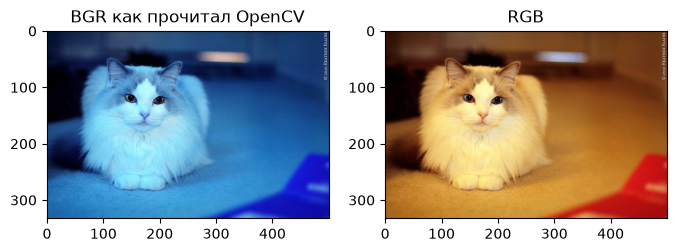

In [ ]:
# Выбираем самое «цветное» фото среди 100 случайных обычных JPEG: на нём ошибка BGR/RGB заметнее
best, best_score = None, -1.0
for fn in labels["filename"].sample(frac=1, random_state=0).head(100):
    with Image.open(IMG_DIR / fn) as im:
        if im.format != "JPEG" or im.mode != "RGB":
            continue
        arr = np.asarray(im.resize((64, 64)), dtype=np.float32)[16:48, 16:48]  # центр кадра
    score = float(np.abs(arr[..., 0] - arr[..., 2]).mean())
    if score > best_score:
        best, best_score = fn, score
example_name = best
example_path = IMG_DIR / example_name
print(example_name)

bgr = cv2.imread(str(example_path))
h, w = bgr.shape[:2]
print("type:", type(bgr), "| shape:", bgr.shape, "| dtype:", bgr.dtype)
print("min:", bgr.min(), "| max:", bgr.max())
print("центр (B, G, R):", bgr[h // 2, w // 2])

центр (R, G, B): [242 212 139]


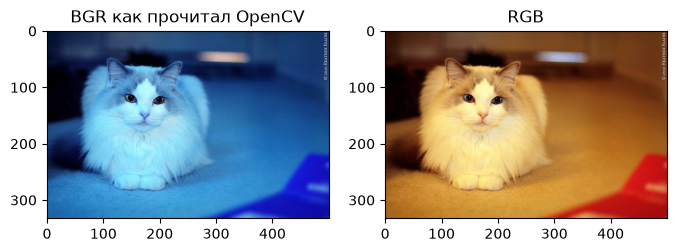

In [11]:
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
print("центр (R, G, B):", rgb[h // 2, w // 2])

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1); plt.imshow(bgr); plt.title("BGR как прочитал OpenCV")
plt.subplot(1, 2, 2); plt.imshow(rgb); plt.title("RGB")
plt.show()

Преобразования. Подсказки:

| Что | Функция |
|---|---|
| оттенки серого | `cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)` |
| ресайз | `cv2.resize(rgb, (224, 224))` |
| отражение | `cv2.flip(rgb, 1)` |

In [12]:
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
resized = cv2.resize(rgb, (224, 224))
flipped = cv2.flip(rgb, 1)
print("gray:", gray.shape, "| resized:", resized.shape, "| flipped:", flipped.shape)


gray: (333, 500) | resized: (224, 224, 3) | flipped: (333, 500, 3)


In [13]:
# Ловушка uint8: запустите и посмотрите, что получилось
a = np.array([[50, 200, 250]], dtype=np.uint8)   # «картинка» 1x3 пикселя
print("numpy a + 100:", a + 100)
print("cv2.add:      ", cv2.add(a, np.full_like(a, 100)))

numpy a + 100: [[150  44  94]]
cv2.add:       [[150 255 255]]


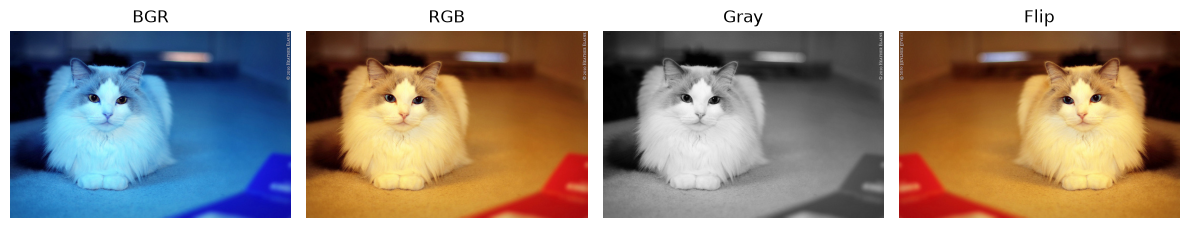

In [14]:
plt.figure(figsize=(12, 3))
plt.subplot(1, 4, 1); plt.imshow(bgr); plt.title("BGR")
plt.subplot(1, 4, 2); plt.imshow(rgb); plt.title("RGB")
plt.subplot(1, 4, 3); plt.imshow(gray, cmap="gray"); plt.title("Gray")
plt.subplot(1, 4, 4); plt.imshow(flipped); plt.title("Flip")
for ax in plt.gcf().axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS / "transforms.png", dpi=110)
plt.show()

## 3. Сводка по датасету

Пройдите по всем файлам в `images/`. Для каждого соберите словарь и добавьте в список `rows`.

`Image.open(p)` из Pillow честно говорит формат (`.format`) и режим (`.mode`: `RGB`, `L`, `RGBA`, `P`). `cv2.imread(p)` по умолчанию всегда отдаёт 3 канала и такие файлы не выдаст.

In [15]:
label_by_file = labels.set_index("filename")

rows = []
for p in sorted(IMG_DIR.iterdir()):
    if p.name.startswith("."):
        continue
    rec = {"filename": p.name, "ext": p.suffix.lower()}

    with Image.open(p) as im:
        rec["pil_format"] = im.format
        rec["mode"] = im.mode
        rec["width"], rec["height"] = im.size

    rec["has_xml"] = (XML_DIR / (p.stem + ".xml")).exists()

    lab = label_by_file.loc[p.name]
    rec["breed"] = lab["breed"]
    rec["species"] = lab["species"]

    rows.append(rec)

info = pd.DataFrame(rows)
info.head()

,filename,ext,pil_format,mode,width,height,has_xml,breed,species
0,Birman_1.jpg,.jpg,JPEG,RGB,375,500,False,Birman,cat
1,Birman_10.jpg,.jpg,JPEG,RGB,500,330,True,Birman,cat
2,Birman_100.jpg,.jpg,JPEG,RGB,500,334,True,Birman,cat
3,Birman_101.jpg,.jpg,JPEG,RGB,500,375,True,Birman,cat
4,Birman_102.jpg,.jpg,JPEG,RGB,332,500,True,Birman,cat


In [16]:
ext_to_fmt = {".jpg": "JPEG", ".jpeg": "JPEG", ".png": "PNG"}
fmt_mismatch = info.apply(lambda r: ext_to_fmt.get(r["ext"]) != r["pil_format"], axis=1)
breed_counts = info["breed"].value_counts()

summary = {
    "variant": VARIANT,
    "n_files": len(info),
    "n_breeds": info["breed"].nunique(),
}
for k, v in info["species"].value_counts().items():
    summary[f"n_{k}"] = int(v)
summary.update({
    "width_min": int(info["width"].min()),
    "width_median": float(info["width"].median()),
    "width_max": int(info["width"].max()),
    "height_min": int(info["height"].min()),
    "height_median": float(info["height"].median()),
    "height_max": int(info["height"].max()),
    "not_rgb": int((info["mode"] != "RGB").sum()),
    "jpg_not_jpeg": int(((info["ext"].isin([".jpg", ".jpeg"])) & (info["pil_format"] != "JPEG")).sum()),
    "ext_format_mismatch": int(fmt_mismatch.sum()),
    "with_xml": int(info["has_xml"].sum()),
    "breed_max_count": int(breed_counts.max()),
    "breed_min_count": int(breed_counts.min()),
})
summary_df = pd.DataFrame(list(summary.items()), columns=["metric", "value"])
summary_df.to_csv(RESULTS / "summary.csv", index=False)
summary_df

,metric,value
0,variant,4.0
1,n_files,806.0
2,n_breeds,4.0
3,n_cat,403.0
4,n_dog,403.0
5,width_min,176.0
6,width_median,500.0
7,width_max,1024.0
8,height_min,150.0
9,height_median,375.0


### Проблемные файлы

Найдите файлы, которые сломают обучение в следующих лабах: режим не `RGB` или формат не совпадает с расширением. Для одного такого файла сравните `cv2.imread(p).shape` и `cv2.imread(p, cv2.IMREAD_UNCHANGED).shape`.

In [17]:
bad_mode = info[info["mode"] != "RGB"]
print("Не RGB:", len(bad_mode))
print(bad_mode[["filename", "pil_format", "mode"]].to_string(index=False))

bad_fmt = info[fmt_mismatch]
print("\nФормат не совпадает с расширением:", len(bad_fmt))
print(bad_fmt[["filename", "ext", "pil_format", "mode"]].to_string(index=False))

problem = pd.concat([bad_mode, bad_fmt]).drop_duplicates("filename")

Не RGB: 0
Empty DataFrame
Columns: [filename, pil_format, mode]
Index: []

Формат не совпадает с расширением: 0
Empty DataFrame
Columns: [filename, ext, pil_format, mode]
Index: []


In [18]:
if len(problem):
    pp = IMG_DIR / problem.iloc[0]["filename"]
    a1 = cv2.imread(str(pp))
    a2 = cv2.imread(str(pp), cv2.IMREAD_UNCHANGED)
    print("Файл:", pp.name)
    print("imread по умолчанию:", None if a1 is None else a1.shape)
    print("IMREAD_UNCHANGED:   ", None if a2 is None else a2.shape)
else:
    print("Проблемных файлов нет")

Проблемных файлов нет


## 4. Разметка и сетка примеров

- XML в формате Pascal VOC: внутри `<object><bndbox>` координаты `xmin, ymin, xmax, ymax`. Есть не у всех изображений, иногда объектов два.
- Trimap: PNG того же размера, что и фото. 1 = животное, 2 = фон, 3 = граница.

In [19]:
def read_boxes(xml_path):
    # Все боксы из XML: список (xmin, ymin, xmax, ymax)
    root = ET.parse(xml_path).getroot()
    return [tuple(int(float(bb.find(k).text)) for k in ("xmin", "ymin", "xmax", "ymax"))
            for bb in root.iter("bndbox")]

name_xml = info[info["has_xml"]].iloc[0]["filename"]
stem = Path(name_xml).stem
print(name_xml, "боксы:", read_boxes(XML_DIR / (stem + ".xml")))

trimap = cv2.imread(str(TRIMAP_DIR / (stem + ".png")), cv2.IMREAD_UNCHANGED)
print("trimap shape:", trimap.shape, "| dtype:", trimap.dtype, "| значения:", np.unique(trimap))

print(info.groupby(["breed", "has_xml"]).size())

Birman_10.jpg боксы: [(45, 103, 194, 225)]
trimap shape: (330, 500) | dtype: uint8 | значения: [1 2 3]
breed               has_xml
Birman              False      101
                    True       100
Ragdoll             False      102
                    True       100
german_shorthaired  False      100
                    True       101
pug                 False      100
                    True       102
dtype: int64


Сетка: по одному фото каждой породы с боксом головы. Бокс рисуется так: `cv2.rectangle(rgb, (x0, y0), (x1, y1), (0, 255, 0), 3)`. Берите фото, у которых есть XML.

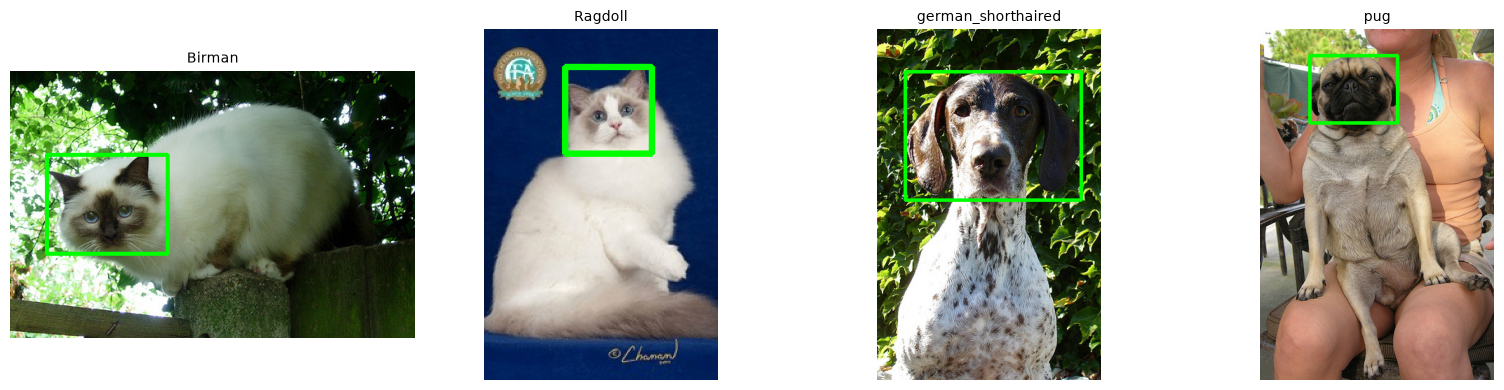

In [20]:
picks = []
for b in variant_info["breeds"]:
    sub = info[info["breed"] == b]
    with_box = sub[sub["has_xml"]]
    picks.append((b, (with_box if len(with_box) else sub).iloc[0]))

plt.figure(figsize=(4 * len(picks), 4))
for i, (b, r) in enumerate(picks, start=1):
    img = cv2.cvtColor(cv2.imread(str(IMG_DIR / r["filename"])), cv2.COLOR_BGR2RGB)
    title = b
    if r["has_xml"]:
        for (x0, y0, x1, y1) in read_boxes(XML_DIR / (Path(r["filename"]).stem + ".xml")):
            cv2.rectangle(img, (x0, y0), (x1, y1), (0, 255, 0), 3)
    else:
        title += " (нет XML)"
    plt.subplot(1, len(picks), i)
    plt.imshow(img)
    plt.title(title, fontsize=10)
    plt.axis("off")
plt.tight_layout()
plt.savefig(RESULTS / "samples_grid.png", dpi=110)
plt.show()

## 5. Числа для отчёта и выгрузка

Напечатайте всё, что понадобится в README. Затем упакуйте `results/` в архив и скачайте:
- в Kaggle: правая панель → Output → `results.zip` → Download; ноутбук: File → Download Notebook;
- в Colab: архив скачается сам после запуска ячейки; ноутбук: File → Download → Download .ipynb;
- локально: ничего скачивать не нужно, всё уже лежит в папке `lab01/`.

Переименуйте скачанный ноутбук в `solution.ipynb`.

In [21]:
print(summary_df.to_string(index=False))

expected = {"summary.csv", "transforms.png", "samples_grid.png"}
missing = expected - {p.name for p in RESULTS.iterdir()}
print("не хватает:", missing if missing else "ничего, все 3 файла на месте")

             metric  value
            variant    4.0
            n_files  806.0
           n_breeds    4.0
              n_cat  403.0
              n_dog  403.0
          width_min  176.0
       width_median  500.0
          width_max 1024.0
         height_min  150.0
      height_median  375.0
         height_max  900.0
            not_rgb    0.0
       jpg_not_jpeg    0.0
ext_format_mismatch    0.0
           with_xml  403.0
    breed_max_count  202.0
    breed_min_count  201.0
не хватает: ничего, все 3 файла на месте


In [23]:
import shutil
if ENV != "local":
    archive = shutil.make_archive("results", "zip", RESULTS)
    print("архив:", archive)
    if ENV == "colab":
        from google.colab import files
        files.download(archive)